In [1]:
import numpy as np
from scipy.integrate import *
from numpy.fft import *
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import matplotlib.animation as animation
from IPython.display import HTML, display
from matplotlib.ticker import ScalarFormatter
from types import SimpleNamespace
import pickle
from tqdm.auto import tqdm
import os
import glob
import sab2

# Adatok beolvasása
A *Modell* objektumokat elkészítjük, adataikat kinyerjük.

In [2]:
def read_data(source, t):
    folder_path = source

    file_pattern = os.path.join(folder_path, '*.pkl')
    file_list = glob.glob(file_pattern)

    t_vals=np.linspace(0,t,100*t)

    runs=[]

    #Adatok beolvasása a mappából
    for file_path in file_list:
        run =sab2.Modell(file_path)
        runs.append(run)

    print(f'Beolvasott mappa: {source}')
    print(f"Összesen {len(runs)} fájl lett beolvasva.")

    return np.array(runs)



In [ ]:
runs=read_data('/home/c_abcsl3/c_abc/LILI/SAB/o300/data/process', 200)

Beolvasott mappa: /home/c_abcsl3/c_abc/LILI/SAB/o300/data/process
Összesen 25 fájl lett beolvasva.


In [18]:
btest=read_data('/home/c_abcsl3/c_abc/LILI/SAB/o300/data/btest', 200)

Beolvasott mappa: /home/c_abcsl3/c_abc/LILI/SAB/o300/data/btest
Összesen 10 fájl lett beolvasva.


In [4]:
for obj in tqdm(runs):
    t_vals=np.linspace(0,200,100*200)
    obj.solution_divider(t_vals)
    obj.energy_calc()

  0%|          | 0/25 [00:00<?, ?it/s]

In [20]:
for obj in tqdm(btest):
    t_vals=np.linspace(0,200,100*200)
    obj.solution_divider(t_vals)
    obj.energy_calc()

  0%|          | 0/10 [00:00<?, ?it/s]

# Csatolás vizsgálata
A külső és belső golyók közötti potenciál erősségét szabályozó $\beta$ paraméter jelentősége --> Mekkora legyen a csatolás?

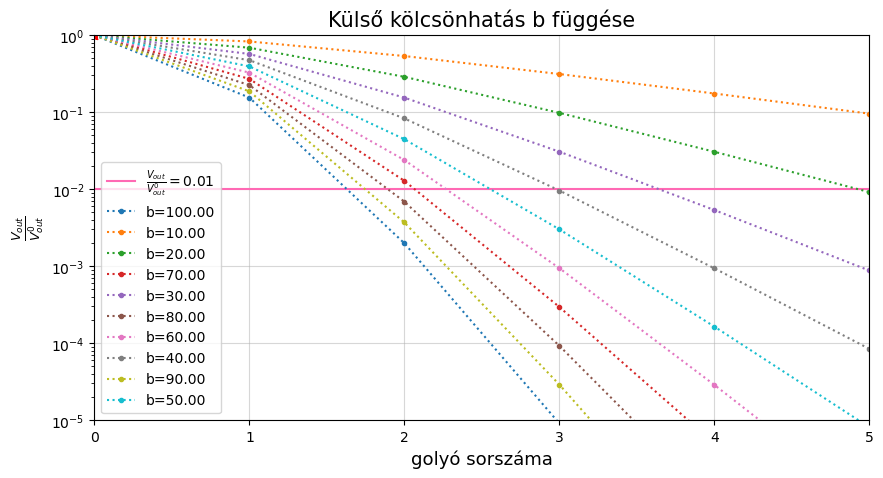

In [22]:
fig,ax=plt.subplots(figsize=(10,5))
plt.grid(alpha=0.5)
plt.xlabel('golyó sorszáma', size=13)
plt.ylabel(r'$\frac{V_{out}}{V_{out}^{0}}$', size=13)
plt.title('Külső kölcsönhatás b függése', size=15)
plt.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
plt.plot((0,16), (1/100 , 1/100), label=r'$\frac{V_{out}}{V_{out}^{0}} = 0.01$', color='hotpink')

for obj in btest:
    idx = np.where(obj.V_out[0, :] <= obj.V_out[0, 0] / 100)[0][0] #Ahol a kölcsönhatás erőssége a fele aká csökken
    V_half = obj.V_out[0, idx]
    n_half = range(obj.n)[idx]
    
    plt.plot(range(obj.n), obj.V_out[0,:]/obj.V_out[0,0], label=f'b={obj.b:.2f}', marker='o', markersize=3, linestyle=':') #Leosztva a max értékkel.
    plt.plot(n_half, V_half/obj.V_out[0,0], marker='*', markersize='8', color='red')
    
plt.legend()
plt.xlim(0,5)
plt.ylim(1e-5,1)
ax.set_yscale('log')

# Külső sebesség változtatása
Különböző kezdősebességekkel elindítva a külső golyót, létszika  várt jelenség --> Hogyan különböznek a különböző kezdősebességgel indított futások?

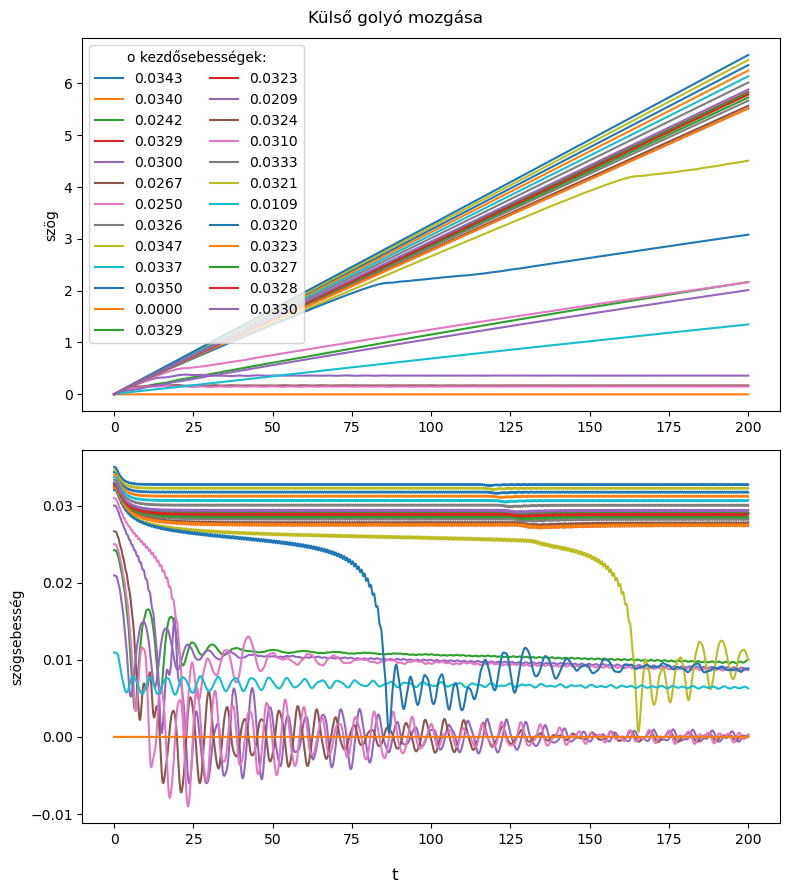

In [7]:
fig,ax=plt.subplots(2,1, figsize=(8,9))
fig.supxlabel('t')
fig.suptitle('Külső golyó mozgása')
    
for obj in runs:
        ax[0].plot(obj.t,obj.theta, label=f'{obj.o:.4f}')
        ax[1].plot(obj.t,obj.Omega)
    
ax[0].legend(ncols=2, title='o kezdősebességek:')
ax[0].set_ylabel('szög')
ax[1].set_ylabel(r'szögsebesség')
#ax[1].hlines(2/3*np.pi/100, 0, 200, color='red', label=r'$o_c=\frac{2\pi}{300}$')

plt.tight_layout()

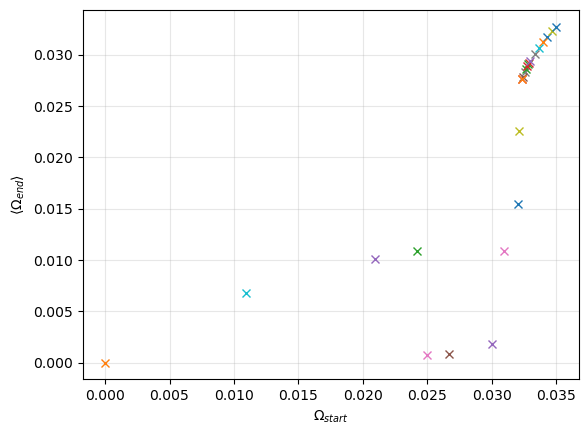

In [11]:
for run in runs:
    plt.plot(run.o, np.mean(run.Omega[:-50]), 'x')

plt.xlabel(r'$\Omega_{start}$')
plt.ylabel(r'$\langle \Omega _{end}\rangle$')
plt.grid(alpha=0.3)